<a href="https://colab.research.google.com/github/harleenk2295-cpu/c-practice/blob/main/ica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('/content/archive (3).zip')

# Define features and target variable
X = df.drop(['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target'], axis=1)
y = df['target']

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the model (RandomForest in this case)
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model to the training data
model.fit(X_train, y_train)

# Get the original accuracy
original_accuracy = model.score(X_test, y_test)

# Perform Permutation Importance
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

# Get the feature importances
importance = result.importances_mean

# Print accuracy of the model for each feature
print(f"Original model accuracy: {original_accuracy:.4f}")
print("\nAccuracy decrease when permuting each feature:")

# Loop through each feature and print the accuracy drop
for i, feature in enumerate(X.columns):
    permuted_accuracy = original_accuracy - importance[i]
    print(f"{feature}: Decrease in accuracy = {importance[i]:.4f}, Permuted accuracy = {permuted_accuracy:.4f}")


Original model accuracy: 0.7213

Accuracy decrease when permuting each feature:
age: Decrease in accuracy = 0.0033, Permuted accuracy = 0.7180
trestbps: Decrease in accuracy = 0.0033, Permuted accuracy = 0.7180
chol: Decrease in accuracy = 0.0131, Permuted accuracy = 0.7082
thalach: Decrease in accuracy = 0.1049, Permuted accuracy = 0.6164
oldpeak: Decrease in accuracy = 0.1246, Permuted accuracy = 0.5967


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import numpy as np

# Load dataset
df = pd.read_csv('/content/archive (3).zip')

# Define features and target variable
X = df.drop(['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target'], axis=1)
y = df['target']

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the model (RandomForest in this case)
model = SVC()
# Train the model on the original dataset
model.fit(X_train, y_train)
original_accuracy = model.score(X_test, y_test)
print(f"Original model accuracy: {original_accuracy:.4f}")

# Dictionary to store the accuracy for each feature replacement
accuracy_dict = {}

# Loop over each feature
for feature in X.columns:
    # Replace the feature values in both train and test sets with the mean of that feature
    X_train_copy = X_train.copy()
    X_test_copy = X_test.copy()

    feature_mean = X_train_copy[feature].mean()

    X_train_copy[feature] = feature_mean
    X_test_copy[feature] = feature_mean

    # Train the model on the modified dataset
    model.fit(X_train_copy, y_train)

    # Predict on the test set and calculate accuracy
    y_pred = model.predict(X_test_copy)
    accuracy = accuracy_score(y_test, y_pred)

    # Store the accuracy
    accuracy_dict[feature] = accuracy
    print(f"Accuracy with feature '{feature}' replaced by its mean: {accuracy:.4f}")

# Display the accuracy for each feature replacement
print("\nAccuracy when replacing each feature with its mean:")
for feature, acc in accuracy_dict.items():
    print(f"{feature}: {acc:.4f}")

Original model accuracy: 0.7049
Accuracy with feature 'age' replaced by its mean: 0.6885
Accuracy with feature 'trestbps' replaced by its mean: 0.7049
Accuracy with feature 'chol' replaced by its mean: 0.7541
Accuracy with feature 'thalach' replaced by its mean: 0.5246
Accuracy with feature 'oldpeak' replaced by its mean: 0.7049

Accuracy when replacing each feature with its mean:
age: 0.6885
trestbps: 0.7049
chol: 0.7541
thalach: 0.5246
oldpeak: 0.7049


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv('/content/archive (3).zip')

# Define target variable
y = df['target']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize RandomForest model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Dictionary to store accuracy for each feature
accuracy_dict = {}

# Loop over each feature and train the model using just that feature
for feature in X_train.columns:
    # Create a dataframe with just the current feature
    X_train_feature = X_train[[feature]]
    X_test_feature = X_test[[feature]]

    # Train the model on this single feature
    model.fit(X_train_feature, y_train)

    # Predict on the test set and calculate accuracy
    y_pred = model.predict(X_test_feature)
    accuracy = accuracy_score(y_test, y_pred)

    # Store the accuracy for the feature
    accuracy_dict[feature] = accuracy
    print(f"Accuracy with feature '{feature}' only: {accuracy:.4f}")

# Display the accuracy for each feature
print("\nAccuracy for each individual feature:")
for feature, acc in accuracy_dict.items():
    print(f"{feature}: {acc:.4f}")

Accuracy with feature 'age' only: 0.5738
Accuracy with feature 'trestbps' only: 0.5082
Accuracy with feature 'chol' only: 0.5082
Accuracy with feature 'thalach' only: 0.6885
Accuracy with feature 'oldpeak' only: 0.6885

Accuracy for each individual feature:
age: 0.5738
trestbps: 0.5082
chol: 0.5082
thalach: 0.6885
oldpeak: 0.6885


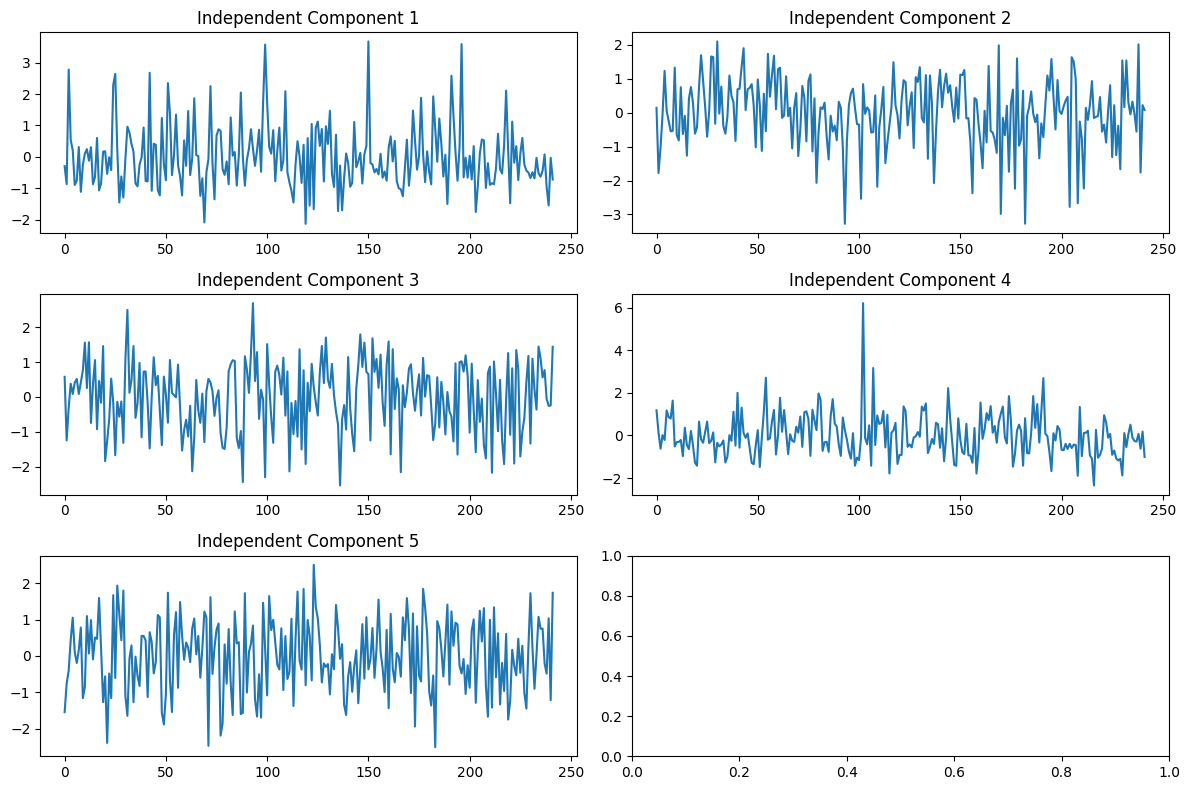

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FastICA
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the heart disease dataset
df = pd.read_csv('/content/archive (3).zip')

# Drop non-numeric features for ICA (for simplicity, we'll use only numerical features)
# If you want to include categorical features, they need to be encoded first
X = df.drop(['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target'], axis=1)
y = df['target']

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the data (ICA is sensitive to scaling, so it's important to standardize the features)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply ICA
ica = FastICA(n_components=5, random_state=42)  # We will extract 5 independent components for visualization
X_train_ica = ica.fit_transform(X_train_scaled)
X_test_ica = ica.transform(X_test_scaled)

# Visualize the independent components
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
axes = axes.ravel()

for i in range(5):
    axes[i].plot(X_train_ica[:, i])
    axes[i].set_title(f"Independent Component {i+1}")

plt.tight_layout()
plt.show()